In [14]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [15]:
# ============================================================
# 1. Reproducibility
# ============================================================

torch.manual_seed(42)


In [16]:
# ============================================================
# 2. Generate training and validation data
# ============================================================

N = 5000

# Randomly sample x from [-100, 100]
x = -100 + 200 * torch.rand(N, 1)

# Target: sin(x)
y = torch.sin(x)

# Shuffle and split 80/20
indices = torch.randperm(N)

train_size = int(0.8 * N)

train_idx = indices[:train_size]
val_idx = indices[train_size:]

x_train = x[train_idx]
y_train = y[train_idx]


x_val = x[val_idx]
y_val = y[val_idx]

In [17]:
# ============================================================
# 3. Normalize the input
# ============================================================
#
# x is originally in [-100, 100].
# We transform it approximately to [-1, 1].
#
# This generally makes neural-network optimization easier.
# ============================================================

x_train_norm = x_train / 100
x_val_norm = x_val / 100



In [18]:
# ============================================================
# 4. Define the neural network
# ============================================================

class SineNet(nn.Module):

    def __init__(self, hidden_layer_width=128):
        super().__init__()

        self.W1 = nn.Parameter(torch.randn(hidden_layer_width, 1))
        self.b1 = nn.Parameter(torch.zeros(hidden_layer_width))

        self.W2 = nn.Parameter(torch.randn(hidden_layer_width, hidden_layer_width))
        self.b2 = nn.Parameter(torch.zeros(hidden_layer_width))

        self.W3 = nn.Parameter(torch.randn(1, hidden_layer_width))
        self.b3 = nn.Parameter(torch.zeros(1))

    def forward(self, x):

        z1 = x @ self.W1.T + self.b1
        a1 = torch.tanh(z1)

        z2 = a1 @ self.W2.T + self.b2
        a2 = torch.tanh(z2)

        y = a2 @ self.W3.T + self.b3
        return y


In [19]:
model = SineNet()

print(model)



SineNet()


In [20]:
# ============================================================
# 5. Loss function and optimizer
# ============================================================

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


In [21]:
# ============================================================
# 6. Training loop
# ============================================================

epochs = 20000

train_losses = []
val_losses = []

for epoch in range(epochs):

    # ----------------------------------------
    # Training mode
    # ----------------------------------------

    model.train()

    # Forward pass
    predictions = model(x_train_norm)

    # Calculate loss
    loss = loss_fn(predictions, y_train)


    # Clear old gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()


    # ----------------------------------------
    # Validation
    # ----------------------------------------

    model.eval()


    with torch.no_grad():

        val_predictions = model(x_val_norm)

        val_loss = loss_fn(
            val_predictions,
            y_val
        )

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())


    # ----------------------------------------
    # Print progress
    # ----------------------------------------


    if (epoch + 1) % 500 == 0:

        print(
            f"Epoch {epoch + 1:5d} | "
            f"Train Loss: {loss.item():.6f} | "
            f"Val Loss: {val_loss.item():.6f}"
        )



Epoch   500 | Train Loss: 0.494022 | Val Loss: 0.533972
Epoch  1000 | Train Loss: 0.492614 | Val Loss: 0.532799
Epoch  1500 | Train Loss: 0.489050 | Val Loss: 0.530352
Epoch  2000 | Train Loss: 0.484261 | Val Loss: 0.527081
Epoch  2500 | Train Loss: 0.480316 | Val Loss: 0.524327
Epoch  3000 | Train Loss: 0.476176 | Val Loss: 0.520895
Epoch  3500 | Train Loss: 0.471151 | Val Loss: 0.516299
Epoch  4000 | Train Loss: 0.464669 | Val Loss: 0.508678
Epoch  4500 | Train Loss: 0.459886 | Val Loss: 0.502923
Epoch  5000 | Train Loss: 0.455267 | Val Loss: 0.496638
Epoch  5500 | Train Loss: 0.450423 | Val Loss: 0.489272
Epoch  6000 | Train Loss: 0.445859 | Val Loss: 0.482310
Epoch  6500 | Train Loss: 0.441873 | Val Loss: 0.476409
Epoch  7000 | Train Loss: 0.438093 | Val Loss: 0.470520
Epoch  7500 | Train Loss: 0.431817 | Val Loss: 0.463442
Epoch  8000 | Train Loss: 0.426394 | Val Loss: 0.456875
Epoch  8500 | Train Loss: 0.421624 | Val Loss: 0.451609
Epoch  9000 | Train Loss: 0.416821 | Val Loss: 0

In [22]:
# ============================================================
# 7. Create interpolation test data
# ============================================================

x_test_inside = torch.linspace(
    -100,
    100,
    1000
).reshape(-1, 1)

y_test_inside = torch.sin(x_test_inside)

x_test_inside_norm = x_test_inside / 100




In [23]:
# ============================================================
# 8. Create extrapolation test data
# ============================================================

x_test_outside = torch.linspace(
    -1000,
    1000,
    1000
).reshape(-1, 1)

y_test_outside = torch.sin(x_test_outside)

x_test_outside_norm = x_test_outside / 100



In [24]:
# ============================================================
# 9. Evaluate the model
# ============================================================

model.eval()

with torch.no_grad():

    pred_inside = model(x_test_inside_norm)

    pred_outside = model(x_test_outside_norm)

    inside_loss = loss_fn(
        pred_inside,
        y_test_inside
    )

    outside_loss = loss_fn(
        pred_outside,
        y_test_outside
    )


print()
print("Evaluation")
print("-----------------------------")
print(f"Interpolation MSE: {inside_loss.item():.6f}")
print(f"Extrapolation MSE: {outside_loss.item():.6f}")




Evaluation
-----------------------------
Interpolation MSE: 0.326193
Extrapolation MSE: 37.045727


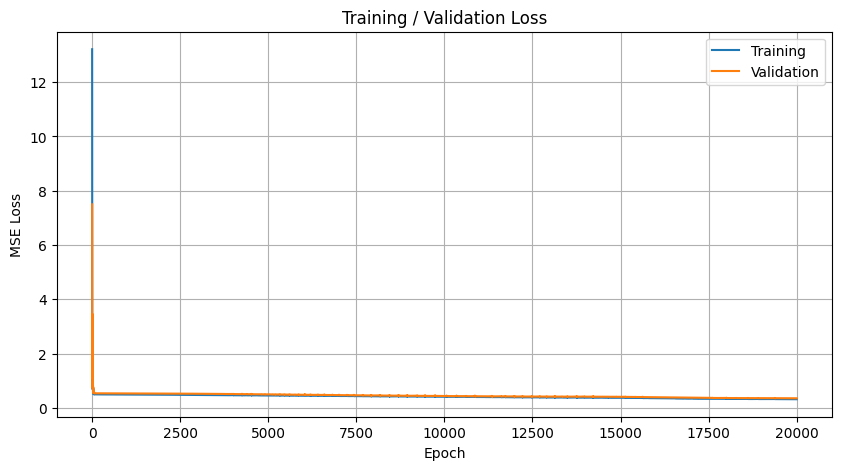

In [25]:
# ============================================================
# 10. Plot training loss
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training / Validation Loss")

plt.legend()
plt.grid(True)

plt.show()



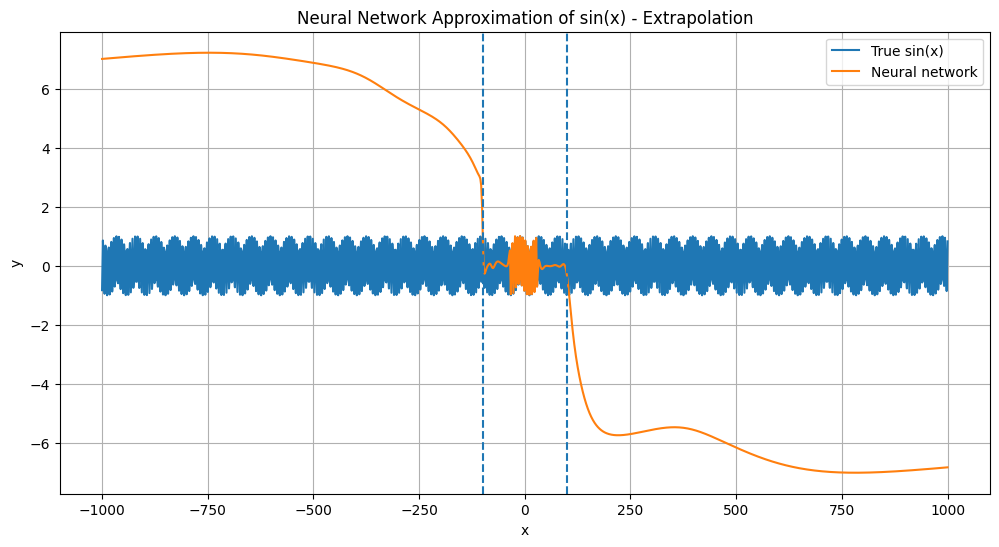

In [26]:
# ============================================================
# 11. Plot learned sine function (extrapolation)
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    x_test_outside.numpy(),
    y_test_outside.numpy(),
    label="True sin(x)"
)

plt.plot(
    x_test_outside.numpy(),
    pred_outside.numpy(),
    label="Neural network"
)

plt.axvline(-100, linestyle="--")
plt.axvline(100, linestyle="--")

plt.xlabel("x")
plt.ylabel("y")


plt.title("Neural Network Approximation of sin(x) - Extrapolation")

plt.legend()
plt.grid(True)

plt.show()

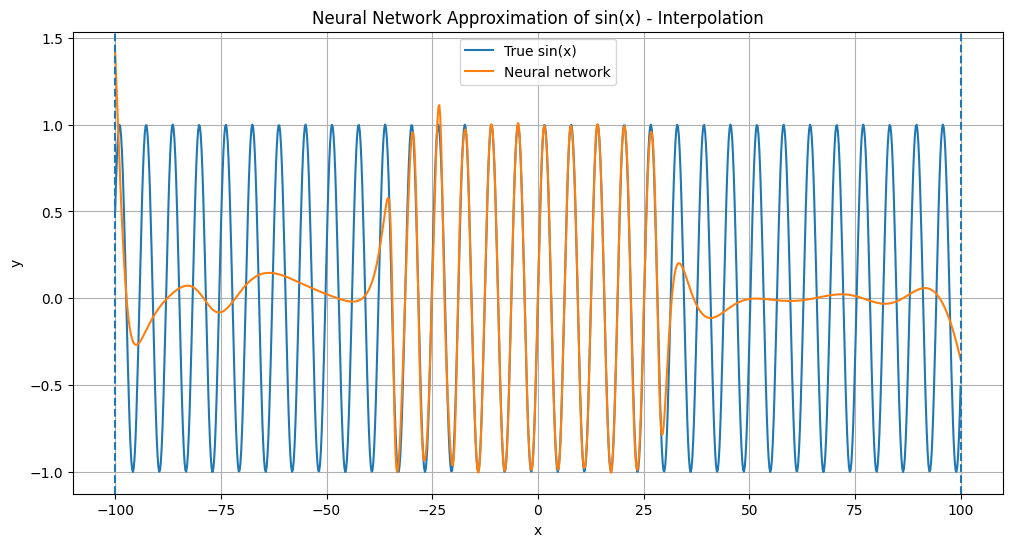

In [27]:
# ============================================================
# 11. Plot learned sine function (same distribution/interpolation)
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    x_test_inside.numpy(),
    y_test_inside.numpy(),
    label="True sin(x)"
)

plt.plot(
    x_test_inside.numpy(),
    pred_inside.numpy(),
    label="Neural network"
)

plt.axvline(-100, linestyle="--")
plt.axvline(100, linestyle="--")

plt.xlabel("x")
plt.ylabel("y")


plt.title("Neural Network Approximation of sin(x) - Interpolation")

plt.legend()
plt.grid(True)

plt.show()